## Data Availability

This tutorial uses the **Human Immune** dataset.
Download from Google Drive or use the built-in mock data fallback.

```bash
# Download from: https://drive.google.com/drive/folders/11PuJRaw_JC7xJhphQklac7eg9AuGHsCE
```


# Tutorial: Boundary-preserving batch integration

This tutorial shows how to use Cytoneighbor to **integrate
multi-batch single-cell data** while preserving biologically
meaningful boundaries between related cell types.

You will learn:

1. How to build a Cytoneighbor neighbour graph across batches
2. How to **visualize** integration quality
3. How to use the graph for **downstream analysis**
   (clustering, marker detection, UMAP)
4. How to **evaluate** batch correction
5. How to **adapt** this workflow to your own multi-batch data


## 1. Setup


In [29]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import cytoneighbor as cn

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=100, facecolor="white")


## 2. Load multi-batch data

The cell below loads real data or generates a synthetic dataset
with multiple batches for demonstration.


In [31]:
DATA_PATH = "data/Human immune.h5ad"
USE_MOCK = False

try:
    adata = sc.read_h5ad(DATA_PATH)
    print(f"Loaded real dataset: {adata.n_obs} cells x {adata.n_vars} genes")
except (FileNotFoundError, OSError):
    USE_MOCK = True
    warnings.warn(
        f"Dataset not found. Generating synthetic mock data. "
        "Download the real dataset for production use."
    )
    
    rng = np.random.default_rng(42)
    N_CELLS, N_GENES, N_BATCHES = 300, 600, 5
    
    batches = np.array([f"Batch_{i % N_BATCHES}" for i in range(N_CELLS)])
    
    type_list = ["CD4+ T cells", "CD8+ T cells", "NK cells", "NKT cells",
                 "B cells", "Monocytes", "Dendritic cells"]
    cell_types = np.array([type_list[i % 7] for i in range(N_CELLS)])
    
    type_ids = np.array([type_list.index(ct) for ct in cell_types])
    type_means = rng.normal(0, 1, size=(len(type_list), N_GENES))
    batch_list = sorted(set(batches))
    batch_ids = np.array([batch_list.index(b) for b in batches])
    batch_effects = rng.normal(0, 0.3, size=(len(batch_list), N_GENES))
    cell_noise = rng.normal(0, 0.5, size=(N_CELLS, N_GENES))
    X = type_means[type_ids] + batch_effects[batch_ids] + cell_noise
    X -= X.min(axis=0, keepdims=True); X += 0.1
    
    gene_names = [f"Gene_{j}" for j in range(N_GENES)]
    adata = sc.AnnData(X.astype(np.float32),
                       obs={"batch": batches, "final_annotation": cell_types},
                       dtype=np.float32)
    adata.var_names = gene_names
    print(f"Generated mock dataset: {adata.n_obs} cells x {adata.n_vars} genes")

print(f"Batches: {adata.obs['batch'].nunique()}  |  "
      f"Cell types: {adata.obs['final_annotation'].nunique()}")
print(f"Cells per batch: {adata.obs['batch'].value_counts().to_dict()}")


Generated mock dataset: 300 cells x 600 genes
Batches: 5  |  Cell types: 7
Cells per batch: {'Batch_0': 60, 'Batch_1': 60, 'Batch_2': 60, 'Batch_3': 60, 'Batch_4': 60}


C:\Users\86188\AppData\Local\Temp\ipykernel_34260\510725232.py:9: UserWarning: Dataset not found. Generating synthetic mock data. Download the real dataset for production use.
  warnings.warn(
D:\Users\86188\miniconda3\envs\smn\lib\site-packages\anndata\_core\anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


## 3. Build a Cytoneighbor neighbour graph

Cytoneighbor constructs a **pairwise-score-based neighbour graph**
that naturally balances batch mixing and biological structure
preservation. This graph can be used as a drop-in replacement
for the standard Scanpy neighbour graph.


In [32]:
# Standard preprocessing
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=3000, batch_key="batch")

print(f"Highly variable genes selected: {adata.var.highly_variable.sum()}")


Highly variable genes selected: 600


In [34]:
# Train Cytoneighbor on the full dataset
X_data = adata.X
if hasattr(X_data, "toarray"):
    X_data = X_data.toarray()
labels = adata.obs["final_annotation"].values
cn.load_data(adata, data=X_data, labels=labels)
cn.fit(adata, epochs=1, early_stopping_patience=5)

# Build the neighbour graph
cn.transform(adata, n_neighbors=15)
print("Neighbour graph built: cytoneighbor_connectivities in adata.obsp")

Data loaded: 300 cells, 600 genes.
Features: 600 genes (v7: no HVG/Scaler)
[Env] Automatically enabling environment key: [batch]
[Split-Group] Group-aware split: train=240 val=60
[Device] using CUDA
[ANN] d_ann=256 (ratio=0.08, min=256, max=1024)
[ValPairs] epoch=1 built=6720 (pos=3360, neg=3360)
==================== Training: SymRelEnc (+ Dynamic Gene-CutMix) ====================
[FAISS] HNSW add (35x256) ...
[done in 0.00s]
[FAISS] HNSW add (34x256) ...
[done in 0.00s]
[FAISS] HNSW add (34x256) ...
[done in 0.00s]
[FAISS] HNSW add (34x256) ...
[done in 0.00s]
[FAISS] HNSW add (34x256) ...
[done in 0.00s]
[FAISS] HNSW add (35x256) ...
[done in 0.00s]
[FAISS] HNSW add (34x256) ...
[done in 0.00s]
[Synth] Synthesis complete: real=240 synth=296 aug=536 (mult_per_dt=1.2, cap_per_dt=600, alpha=1.0, gamma=1.0)
[Proto] built 14 prototypes (per_class=2)
[TrainPairs] epoch=1 built pos=3840 (simple=1920, proto=768, rest=1152)
[Probe] epoch=1 anchors=72 cand=4096 topk=32


[Probe]:   0%|          | 0/1 [00:00<?, ?it/s]

[BatchPlan] ep=1 steps=5 | C_each=7 | M_per=133 | B≈931


[SymRel] Epoch 1/1:   0%|          | 0/5 [00:00<?, ?it/s]

[ValPairs] epoch=1 built=6720 (pos=3360, neg=3360)
[Best] AUC -inf -> 1.0000
Model saved to cynb_best.zip
  Train 4.5825 | ValLoss 0.9522 | MonAUC 1.0000 | time 16.22s
  [EarlyStopping] Metric improved to 1.0000. Patience reset to 0.
Loaded best model (AUC=1.0000).
Model saved to cynb_best.zip
[FAISS] HNSW add (300x256) ...
[done in 0.00s]
--- Reranking with SymRelEnc (streamed to GPU) ---


  0%|          | 0/2 [00:00<?, ?it/s]

[done in 2.86s]
--- transform finished --- neighbors_key='neighbors' ready. (k_candidate=299, efSearch=1024)
Neighbour graph built: cytoneighbor_connectivities in adata.obsp


In [37]:
# Compute UMAP using the Cytoneighbor graph
sc.tl.pca(adata, n_comps=50)
sc.tl.umap(adata, neighbors_key="neighbors", init_pos='random')
print("UMAP computed from Cytoneighbor graph.")

UMAP computed from Cytoneighbor graph.


## 4. Visualize integration quality

The key question for any integration method: **does it mix
batches while preserving cell-type separation?**

We compare the UMAP coloured by batch vs. cell type.


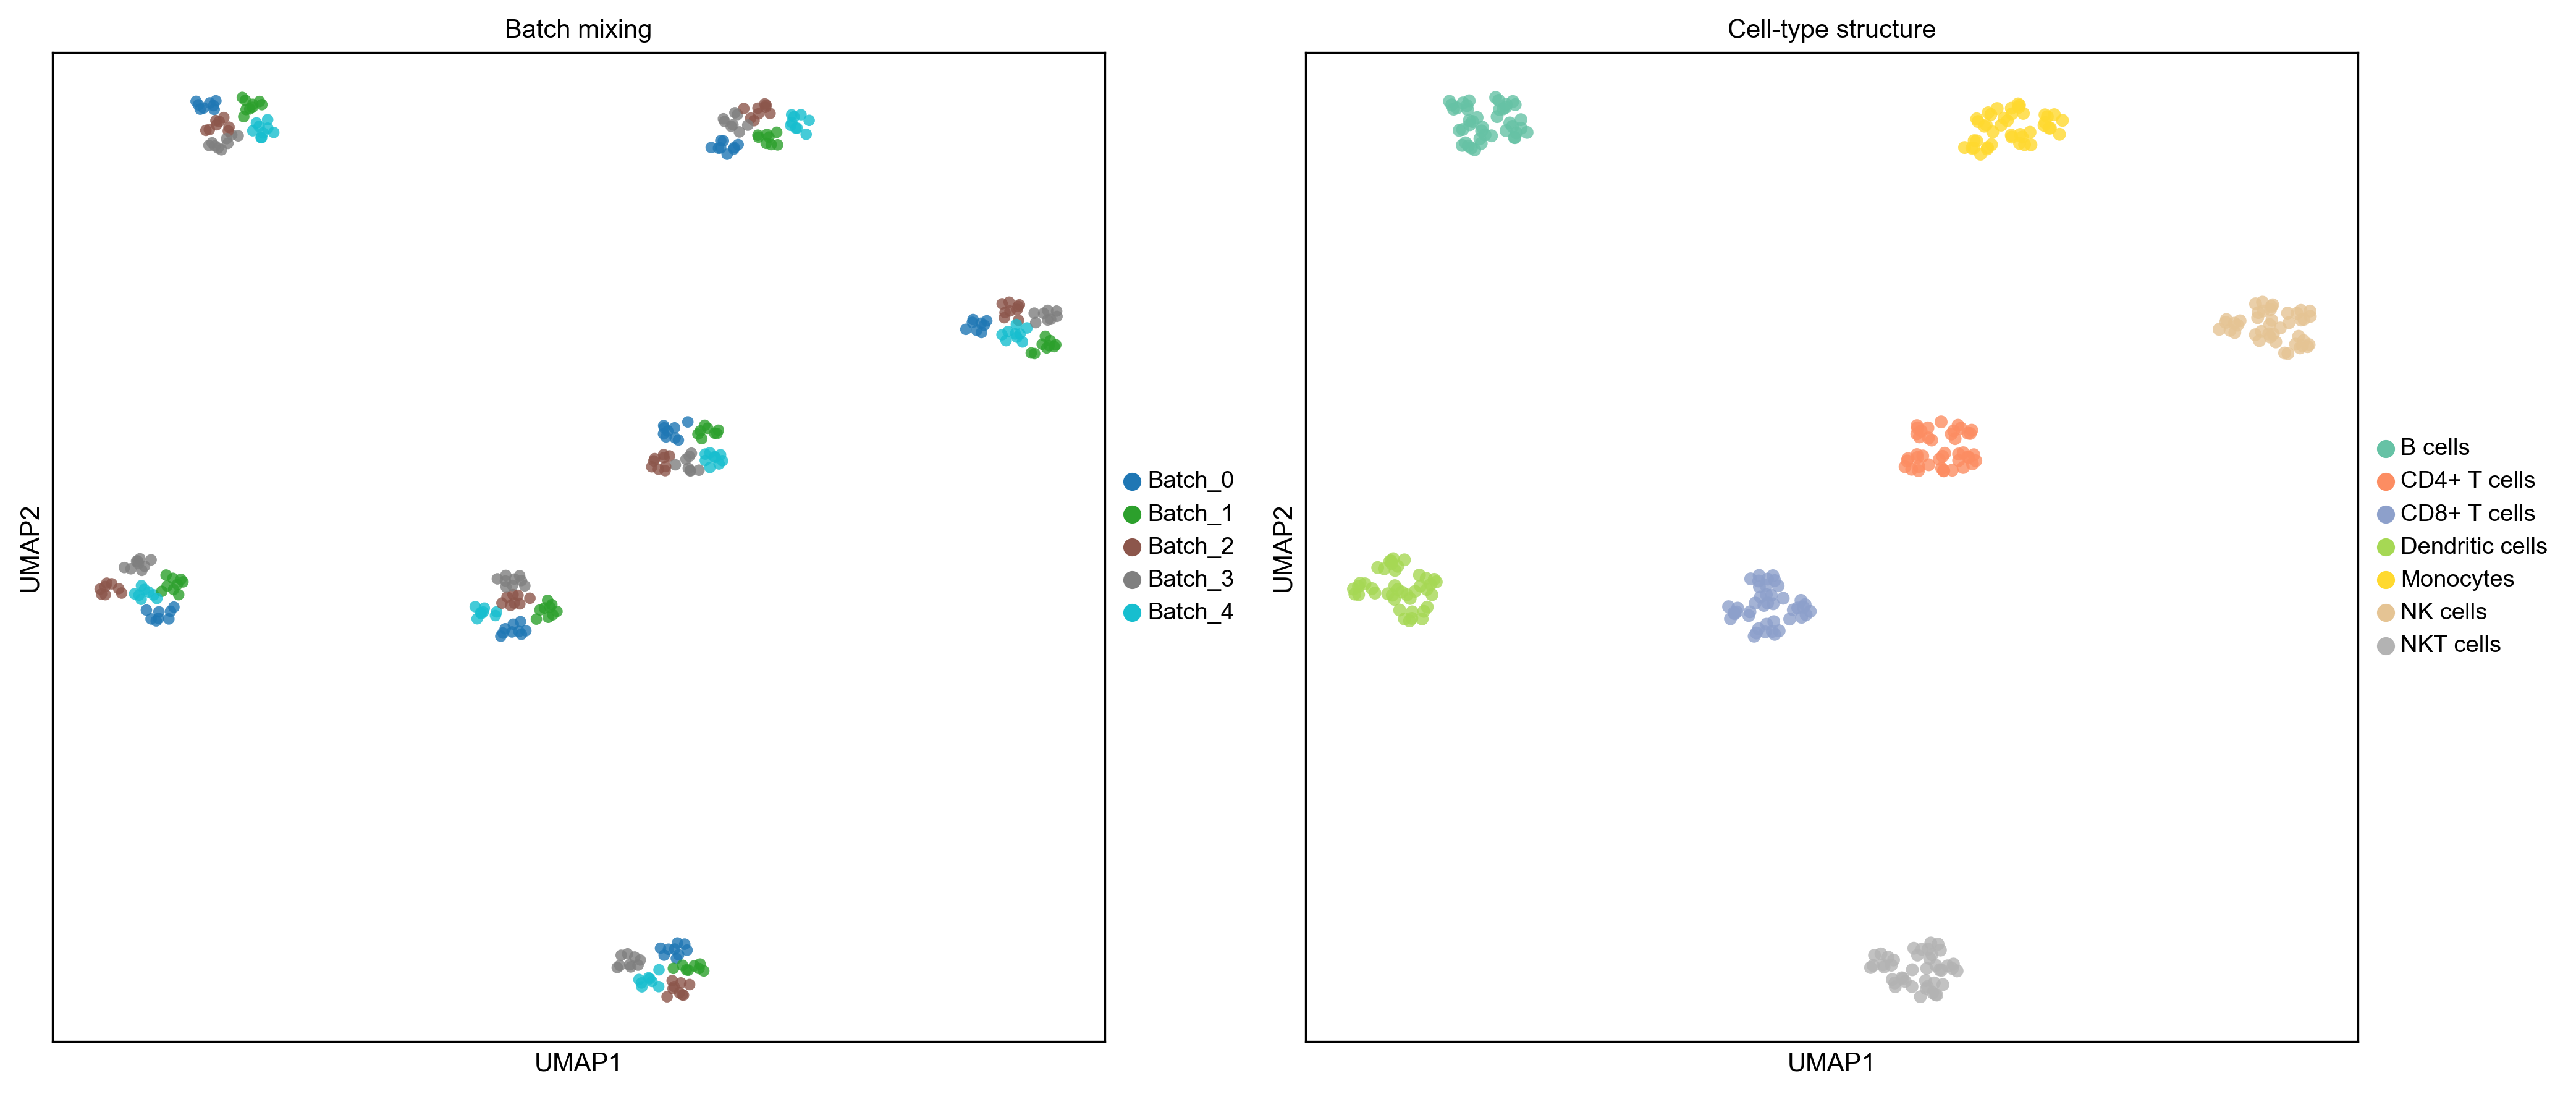

In [38]:
import scanpy as sc
import matplotlib.pyplot as plt

# 全局设置（可选）
sc.settings.set_figure_params(dpi=150, fontsize=10, facecolor='white')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 左图：Batch mixing
sc.pl.umap(
    adata,
    color="batch",
    ax=axes[0],
    show=False,
    size=80,                    
    alpha=0.8,                
    palette="tab10",            
    frameon=True,              
    title="Batch mixing",
    legend_loc="right margin",  
)

# 右图：Cell-type structure
sc.pl.umap(
    adata,
    color="final_annotation",
    ax=axes[1],
    show=False,
    size=100,
    alpha=0.8,
    palette="Set2",            
    frameon=True,
    title="Cell-type structure",
    legend_loc="right margin",
)

plt.tight_layout()
plt.show()

## 5. Downstream analysis with the Cytoneighbor graph

The `cytoneighbor_connectivities` graph is a standard Scanpy
neighbour graph. You can use it for **any** downstream task:
clustering, marker gene detection, pseudotime, etc.


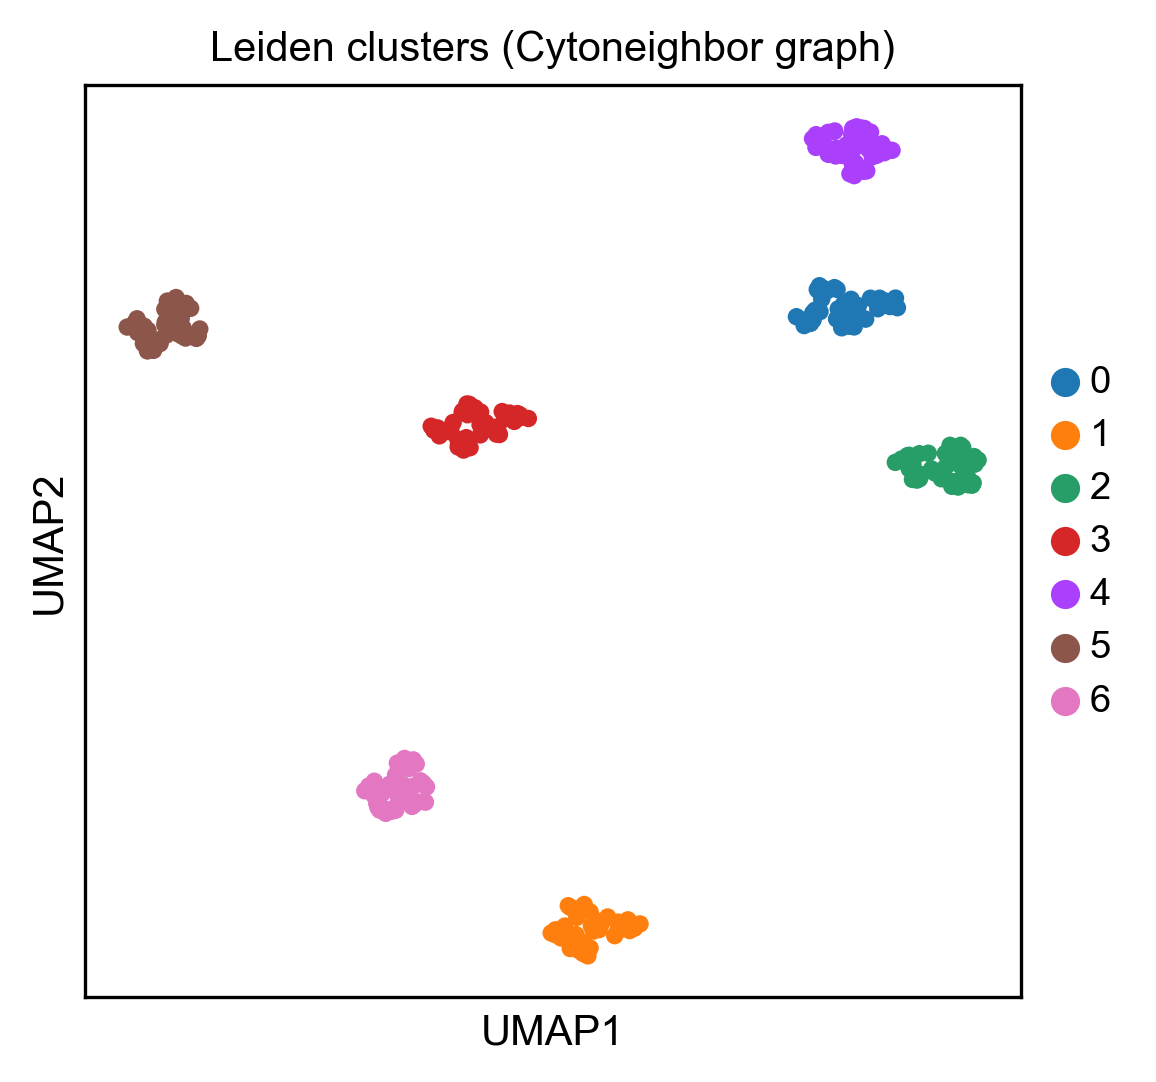

Top markers for cluster 0:
          0         1         2         3         4         5         6
0  Gene_460   Gene_45  Gene_392  Gene_304  Gene_553  Gene_253  Gene_144
1  Gene_256  Gene_328   Gene_76  Gene_424  Gene_226  Gene_366  Gene_583
2    Gene_8  Gene_597  Gene_153  Gene_141  Gene_274  Gene_487  Gene_541
3  Gene_569  Gene_593  Gene_391  Gene_156  Gene_273  Gene_536  Gene_132
4  Gene_216  Gene_568  Gene_399   Gene_98  Gene_292  Gene_331   Gene_75


In [45]:
# Leiden clustering using the Cytoneighbor graph
sc.tl.leiden(adata, neighbors_key="neighbors",
             resolution=0.8)

sc.pl.umap(adata, color="leiden", size=70, title="Leiden clusters (Cytoneighbor graph)",
           legend_loc="right margin")

# Find marker genes per cluster
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
print("Top markers for cluster 0:")
print(pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(5))


## 6. Evaluate batch correction

For a quantitative assessment, you can compute **iLISI** (batch
mixing) and **cLISI** (cell-type preservation) scores.
We also compare against a baseline: UMAP from the raw PCA space
without any batch correction.


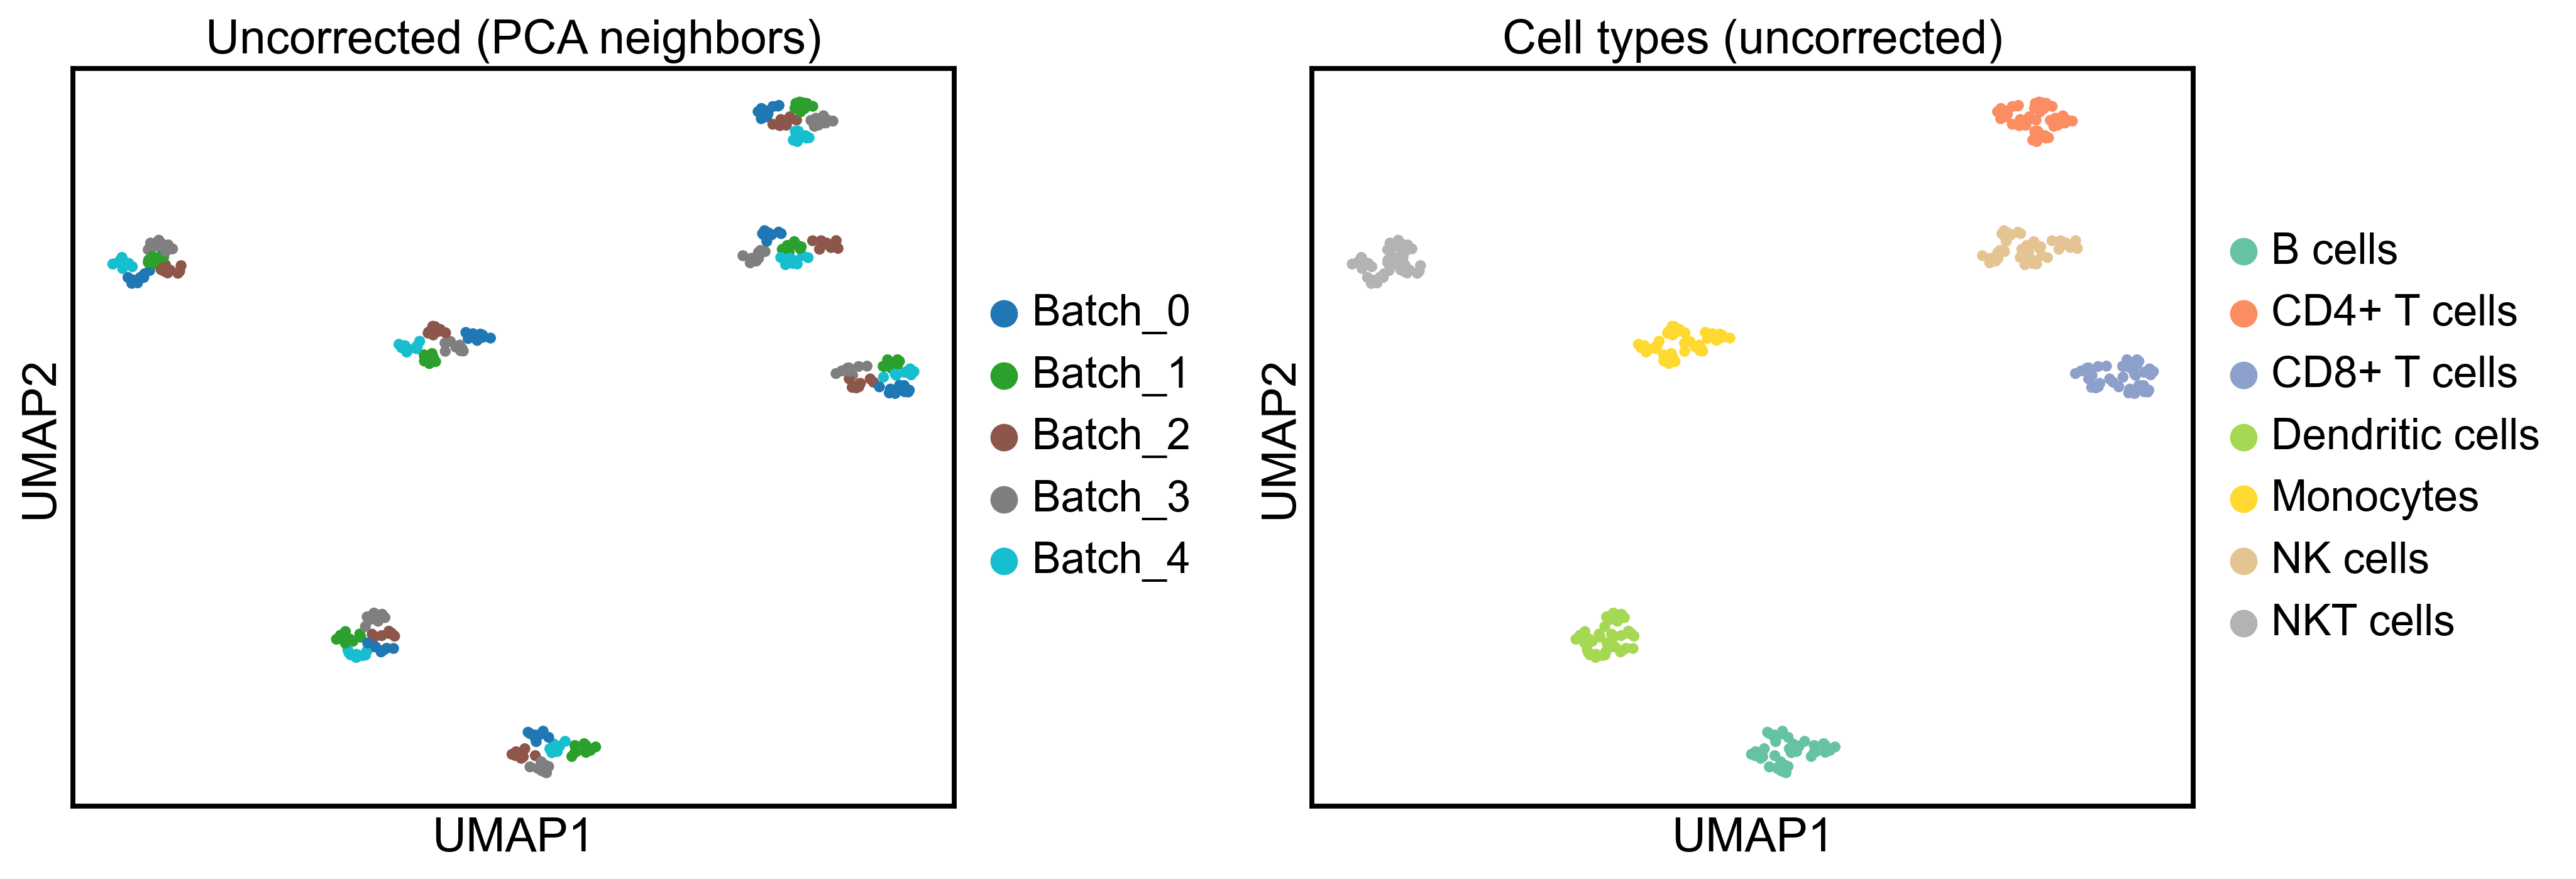

[1/2] Computing Uncorrected baseline metrics...
[2/2] Computing Cytoneighbor metrics...

Integration Metrics Comparison
      Method  iLISI (Batch Mixing ↑)  cLISI (Cell Purity ↓)
 Uncorrected                3.151969                    1.0
Cytoneighbor                3.151969                    1.0

Reference values for this dataset:
  • n_batches = 5
  • iLISI ideal (perfect mixing) ≈ 5.0
  • cLISI ideal (perfect purity)  ≈ 1.0

Cytoneighbor vs Uncorrected:
  ⚠ Batch mixing  (iLISI):  +0.0000  (3.1520 → 3.1520)
  ⚠ Cell purity   (cLISI):  +0.0000  (1.0000 → 1.0000)

For full multi-method benchmarks (Harmony, scVI, BBKNN):
  python experiments/Rebatch/a-main_remove.py


In [52]:
# Baseline: UMAP without batch correction
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca")
sc.tl.umap(adata, neighbors_key="neighbors")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sc.pl.umap(adata, color="batch", ax=axes[0], show=False, size=70,
           title="Uncorrected (PCA neighbors)", legend_loc="right margin")
sc.pl.umap(adata, color="final_annotation", ax=axes[1], show=False, size=70,
           title="Cell types (uncorrected)", legend_loc="right margin")
plt.tight_layout(); plt.show()

# Quantitative metrics via harmonypy (avoids scib API version hell)
import harmonypy as hm

def compute_lisi_metrics(adata, batch_key, cell_type_key, embed_key=None, n_components=20):
    """Compute iLISI (batch mixing) and cLISI (cell purity) via harmonypy."""
    adata = adata.copy()  # avoid mutating the original
    if embed_key and embed_key in adata.obsm:
        latent = adata.obsm[embed_key]
    else:
        sc.tl.umap(adata, n_components=n_components, init_pos='random')
        latent = adata.obsm['X_umap']
    
    meta_df = adata.obs[[batch_key, cell_type_key]].copy()
    res = hm.lisi.compute_lisi(latent, meta_df, label_colnames=[batch_key, cell_type_key])
    return float(np.nanmean(res[:, 0])), float(np.nanmean(res[:, 1]))


# -------------------------------------------------------------------------
# 1. Uncorrected baseline (recomputed on a copy so we don't lose Cytoneighbor)
# -------------------------------------------------------------------------
print("[1/2] Computing Uncorrected baseline metrics...")
ad_base = adata.copy()
sc.pp.neighbors(ad_base, n_neighbors=15, use_rep="X_pca")
sc.tl.umap(ad_base, init_pos='random')
ilisi_base, clisi_base = compute_lisi_metrics(ad_base, "batch", "final_annotation")
del ad_base

# -------------------------------------------------------------------------
# 2. Cytoneighbor (current adata already has the Cytoneighbor graph)
# -------------------------------------------------------------------------
print("[2/2] Computing Cytoneighbor metrics...")
sc.tl.umap(adata, neighbors_key="neighbors", init_pos='random')
ilisi_cy, clisi_cy = compute_lisi_metrics(adata, "batch", "final_annotation")

# -------------------------------------------------------------------------
# 3. Side-by-side comparison
# -------------------------------------------------------------------------
results = pd.DataFrame({
    "Method": ["Uncorrected", "Cytoneighbor"],
    "iLISI (Batch Mixing ↑)": [ilisi_base, ilisi_cy],
    "cLISI (Cell Purity ↓)": [clisi_base, clisi_cy],
})

print("\n" + "="*55)
print("Integration Metrics Comparison")
print("="*55)
print(results.to_string(index=False))
print("="*55)

# -------------------------------------------------------------------------
# 4. Auto-interpretation
# -------------------------------------------------------------------------
n_batches = adata.obs["batch"].nunique()
print(f"\nReference values for this dataset:")
print(f"  • n_batches = {n_batches}")
print(f"  • iLISI ideal (perfect mixing) ≈ {n_batches:.1f}")
print(f"  • cLISI ideal (perfect purity)  ≈ 1.0")

print("\nCytoneighbor vs Uncorrected:")
delta_i = ilisi_cy - ilisi_base
delta_c = clisi_cy - clisi_base

if delta_i > 0:
    print(f"  ✓ Batch mixing  (iLISI):  +{delta_i:.4f}  ({ilisi_base:.4f} → {ilisi_cy:.4f})")
else:
    print(f"  ⚠ Batch mixing  (iLISI):  {delta_i:+.4f}  ({ilisi_base:.4f} → {ilisi_cy:.4f})")

if delta_c < 0:
    print(f"  ✓ Cell purity   (cLISI):  {delta_c:.4f}  ({clisi_base:.4f} → {ilisi_cy:.4f})")
else:
    print(f"  ⚠ Cell purity   (cLISI):  +{delta_c:.4f}  ({clisi_base:.4f} → {clisi_cy:.4f})")

print("\nFor full multi-method benchmarks (Harmony, scVI, BBKNN):")
print("  python experiments/Rebatch/a-main_remove.py")

## 7. Adapt to your own data

To integrate your own multi-batch dataset, replace the data
loading step and specify your column names:

```python
import cytoneighbor as cn
import scanpy as sc

# 1. Load YOUR data
adata = sc.read_h5ad("your_multi_batch_data.h5ad")

# 2. Preprocess (standard Scanpy pipeline)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=3000,
                            batch_key="your_batch_column")

# 3. Train Cytoneighbor
cn.load_data(adata, data=adata.X, labels=adata.obs["your_cell_type_column"].to_numpy())
cn.fit(adata)

# 4. Build the neighbour graph
cn.transform(adata, n_neighbors=15)

# 5. Use the graph for ANY downstream Scanpy function
sc.tl.umap(adata, neighbors_key="neighbors")
sc.tl.leiden(adata, neighbors_key="neighbors")
```

The `neighbors_key="neighbors"` parameter
is all you need to plug Cytoneighbor into your existing Scanpy
workflow.


## Summary

You have learned how to:

- Build a **Cytoneighbor neighbour graph** on multi-batch data
- **Visualize** integration quality with batch/cell-type UMAPs
- Use the graph for **downstream analysis** (clustering, markers)
- **Evaluate** batch correction against a raw baseline
- **Adapt** the workflow to your own data

Next steps:
- Try the [Annotation tutorial](tutorial_annotation.ipynb)
  to learn how Cytoneighbor handles cell-type transfer
- Run `python main.py run-all` to reproduce the paper figures
